# Trí · Đánh giá, so sánh và dự đoán

Xem cách tính metric, điểm test trên cùng 150 ảnh, ca A/C chênh lệch lớn và minh chứng demo. Các bảng và ảnh dự đoán lấy từ kết quả đã lưu của đồ án.

Notebook đã lưu sẵn bảng và hình. Để chạy lại, chọn kernel Python của đồ án trong VS Code hoặc Jupyter rồi bấm **Run All**. Môi trường dùng các gói trong [requirements.txt](../../../requirements.txt) và [requirements-notebook.txt](../../../requirements-notebook.txt).

In [1]:
from pathlib import Path
import json
import sys

cwd = Path.cwd().resolve()
candidates = (cwd, *cwd.parents, cwd / "unet-vs-unetplusplus-polyp")
root = next(
    (folder for folder in candidates if (folder / "project.py").is_file()
     and (folder / "configs" / "protocol_lock.json").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Mở notebook từ thư mục đồ án hoặc thư mục members/<tên>/works_done.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
colors = {"A": "#345e86", "B": "#b76b21", "C": "#187c70"}

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

from PIL import Image as PILImage

def show_saved_image(path, max_width=1050, max_height=650):
    with PILImage.open(path) as image:
        image.thumbnail((max_width, max_height), PILImage.Resampling.LANCZOS)
        display(image)

## Metric trên một mask nhỏ

[metrics.py](metrics.py) dùng sigmoid và ngưỡng 0,5 để tạo mask dự đoán, sau đó tính Dice, IoU, Precision và Recall theo từng ảnh. [evaluate.py](evaluate.py) dùng head cuối cho C, kiểm tra khóa trước khi đọc test và lấy trung bình theo ảnh.

In [2]:
import torch

from members.tri.works_done.metrics import binary_metrics

logits = torch.tensor([[[[2.0, 1.0], [-1.0, -2.0]]]])
truth = torch.tensor([[[[1.0, 0.0], [1.0, 0.0]]]])
predicted = (logits.sigmoid() >= 0.5).int()
kinds = {(1, 1): "TP", (0, 1): "FP", (1, 0): "FN", (0, 0): "TN"}
display(pd.DataFrame({
    "Ô": ["Trên trái", "Trên phải", "Dưới trái", "Dưới phải"],
    "Mask thật": truth.flatten().int().tolist(),
    "Mask dự đoán": predicted.flatten().tolist(),
    "Loại": [kinds[(actual, pred)] for actual, pred in zip(truth.flatten().int().tolist(), predicted.flatten().tolist())],
}).set_index("Ô"))
display(pd.DataFrame([{
    name: metric.item() for name, metric in binary_metrics(logits, truth).items()
}]).round(4))

,Mask thật,Mask dự đoán,Loại
Ô,,,
Trên trái,1,1,TP
Trên phải,0,1,FP
Dưới trái,1,0,FN
Dưới phải,0,0,TN


,dice,iou,precision,recall
0,0.5,0.3333,0.5,0.5


## Kết quả test ghép theo cùng ID ảnh

[compare.py](compare.py) đối chiếu các run trên cùng tập test. Điểm dưới đây đọc từ `results/comparison`. Phần thống kê ghép cặp của [submission_analysis.py](submission_analysis.py) lấy chênh lệch Dice trên từng ảnh và tính khoảng bootstrap với checkpoint cố định. Kết quả thuộc seed 42 trên split Kvasir-SEG của nhóm.

Số ảnh test ghép cặp: 150


,selected_epoch,dice,iou,precision,recall
experiment,,,,,
A,50,0.6014,0.4873,0.6852,0.6267
B,49,0.6682,0.5421,0.7062,0.7370
C,48,0.7390,0.6304,0.7779,0.8007


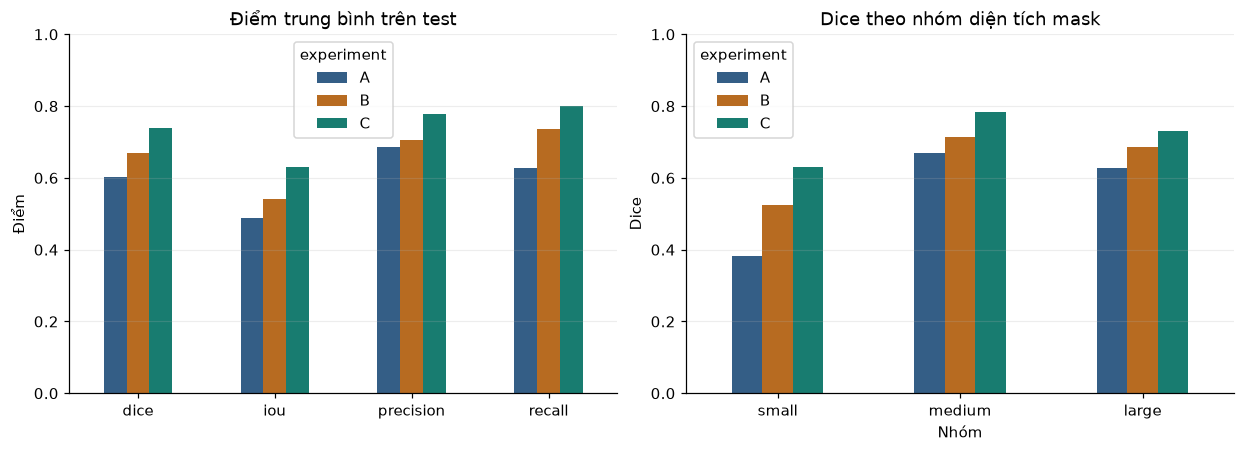

In [3]:
results = root / "results"
comparison = results / "comparison"
evidence = results / "report_figures/checklist_20261114"
scores = pd.read_csv(comparison / "comparison.csv").set_index("experiment")
by_size = pd.read_csv(comparison / "comparison_by_size.csv")
paired = pd.read_csv(comparison / "paired_per_image.csv")
labels = scores.index.tolist()
metrics = ["dice", "iou", "precision", "recall"]
print(f"Số ảnh test ghép cặp: {len(paired)}")
display(scores[["selected_epoch", *metrics]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4), layout="constrained")
scores[metrics].T.plot.bar(ax=axes[0], color=[colors[label] for label in labels], rot=0)
size_scores = by_size.pivot(index="polyp_category", columns="experiment", values="dice")
size_scores.loc[["small", "medium", "large"], labels].plot.bar(
    ax=axes[1], color=[colors[label] for label in labels], rot=0,
)
axes[0].set(title="Điểm trung bình trên test", ylabel="Điểm", xlabel="", ylim=(0, 1))
axes[1].set(title="Dice theo nhóm diện tích mask", ylabel="Dice", xlabel="Nhóm", ylim=(0, 1))
for ax in axes:
    ax.grid(axis="y", alpha=0.22)
plt.show()

,comparison,delta,ci_low,ci_high,images_up,images_down,images_equal
0,B_vs_A,0.0668,0.0330,0.1012,98,51,1
1,C_vs_B,0.0708,0.0491,0.0946,105,45,0
2,C_vs_A,0.1376,0.1024,0.1722,116,34,0


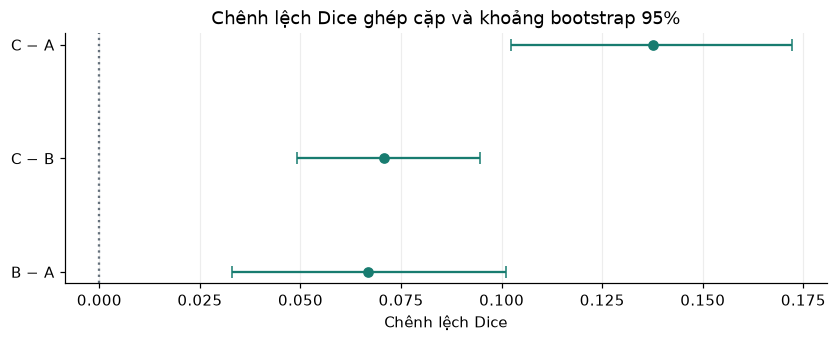

In [4]:
stats = pd.read_csv(evidence / "paired_statistics.csv")
display(stats[["comparison", "delta", "ci_low", "ci_high", "images_up", "images_down", "images_equal"]].round(4))

fig, ax = plt.subplots(figsize=(7.5, 3), layout="constrained")
names = stats["comparison"].str.replace("_vs_", " − ", regex=False)
ax.errorbar(stats["delta"], names, xerr=[stats["delta"] - stats["ci_low"], stats["ci_high"] - stats["delta"]],
            fmt="o", capsize=4, color=colors["C"])
ax.axvline(0, color="#65717c", ls=":")
ax.set(title="Chênh lệch Dice ghép cặp và khoảng bootstrap 95%", xlabel="Chênh lệch Dice")
ax.grid(axis="x", alpha=0.22)
plt.show()

## Hai ảnh nhìn rõ khác biệt A/C

Hai hàng mặc định lấy ca có Dice C−A giảm mạnh nhất và tăng mạnh nhất. Có thể thay `example_ids` bằng các ID khác trong bảng `paired`. Ảnh, mask thật và mask dự đoán được đặt chung hệ tọa độ đầu vào 256×256. Các ca được chọn sau đánh giá để phân tích lỗi.

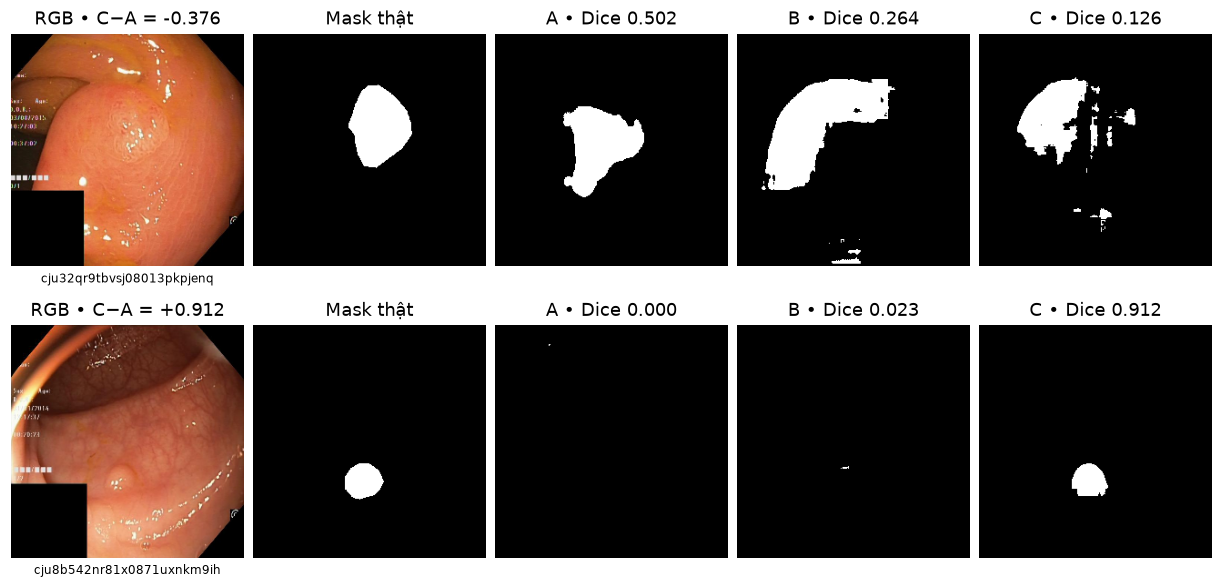

In [5]:
import cv2

from members.khanh.works_done.dataset import DEFAULT_MANIFEST, read_image_unicode

delta = paired["delta_dice_C_minus_A"]
example_ids = paired.loc[[delta.idxmin(), delta.idxmax()], "image_id"].tolist()
manifest = pd.read_csv(DEFAULT_MANIFEST).set_index("image_id")
per_image = paired.set_index("image_id")
height, width = read_json(results / "A_test/summary.json")["preprocessing"]["image_size"]

fig, axes = plt.subplots(len(example_ids), 2 + len(labels),
                         figsize=(11, 2.65 * len(example_ids)), squeeze=False, layout="constrained")
fig.get_layout_engine().set(h_pad=0.075)
for row_axes, image_id in zip(axes, example_ids):
    row = manifest.loc[image_id]
    rgb = read_image_unicode(root / row["image_path"].replace("\\", "/"), cv2.IMREAD_COLOR)
    mask = read_image_unicode(root / row["mask_path"].replace("\\", "/"), cv2.IMREAD_GRAYSCALE)
    original = cv2.resize(cv2.cvtColor(rgb, cv2.COLOR_BGR2RGB), (width, height))
    gt = cv2.resize((mask > 127).astype("uint8"), (width, height), interpolation=cv2.INTER_NEAREST)
    row_axes[0].imshow(original)
    row_axes[0].set_title(f"RGB • C−A = {per_image.loc[image_id, 'delta_dice_C_minus_A']:+.3f}")
    row_axes[0].set_xlabel(image_id, fontsize=8)
    row_axes[1].imshow(gt, cmap="gray", vmin=0, vmax=1)
    row_axes[1].set_title("Mask thật")
    for ax, label in zip(row_axes[2:], labels):
        with PILImage.open(results / f"{label}_test" / "masks" / f"{image_id}.png") as prediction:
            ax.imshow(prediction.convert("L"), cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{label} • Dice {per_image.loc[image_id, f'dice_{label}']:.3f}")
    for ax in row_axes:
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set_visible(False)
plt.show()

## Output của demo Streamlit

[predict.py](predict.py) lưu mask kích thước đầu vào, mask kích thước gốc và ảnh overlay. Với kích thước gốc, mã nội suy xác suất trước khi áp ngưỡng. [demo.py](demo.py) dùng cùng hàm dự đoán. Dưới đây là ảnh chụp demo đã lưu.

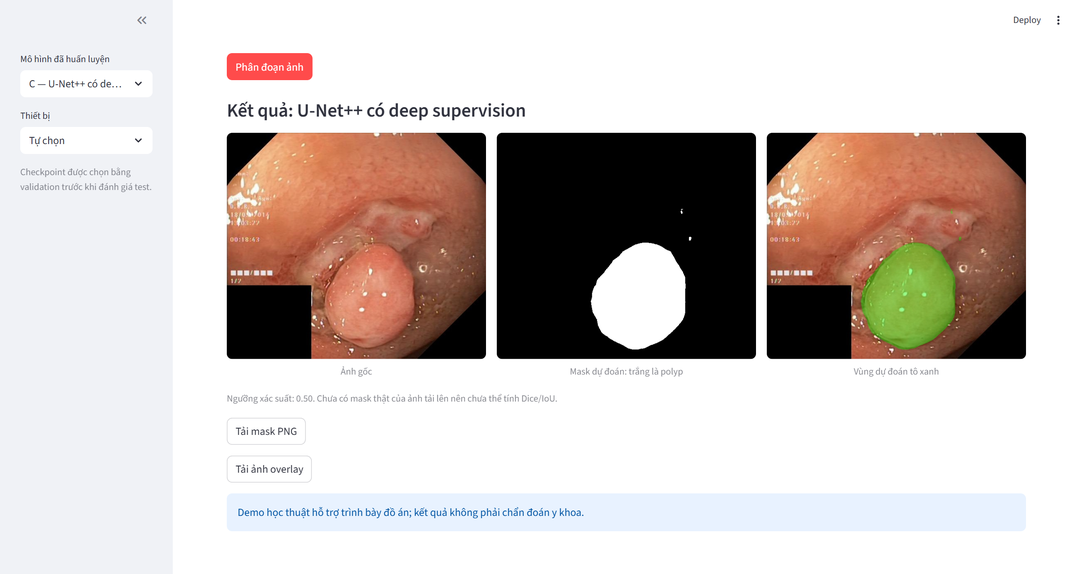

In [6]:
show_saved_image(evidence / "f4_11_demo_test_result.png", max_width=1080, max_height=740)

Muốn thử một ảnh khác, chuẩn bị checkpoint bằng `CacFileSource.py prepare` rồi mở `CacFileSource.py demo` từ thư mục gốc bằng cùng Python của đồ án. Hướng dẫn và tùy chọn CLI nằm trong [README](../../../README.md).